# Evaluation of Fuzzy Method / Model

This notebook evaluates Sillage's **Mamdani fuzzy recommendation model** using seven synthetic traveler scenarios and the **50 European destinations** in `european_city_destination_dataset_preprocessed.csv`. It retains the original 19 questionnaire themes and 27 fuzzy IF–THEN rules.

The destination values are explicitly marked `SYNTHETIC_PLACEHOLDER`. Results demonstrate **technical behavior under assumptions**, not real-world destination quality. We distinguish PASS, FAIL and INCONCLUSIVE.


## Data

**Scenario inputs.** The seven profiles contain all 16 written Profile themes, including both answers to the Profile Travel Pace question (17 profile answer fields in total), and all 12 Trip themes. Trip details (traveler count, ages, duration and dates) are stored separately for each scenario.

**Destination data.** The accompanying `european_city_destination_dataset_preprocessed.csv` contains 50 European destinations and named attributes measured on [0,1], categorical landscape/climate flags, and `daily_cost_eur_estimate`. It does **not** contain the former `t1`–`t27` columns or 1–9 scores. A transparent mapping below adapts it to the questionnaire themes. Some themes remain unmeasurable (not silently guessed).


The enriched CSV's added transport and shared-experience fields are synthetic derived proxies. The current transport-mode flags may not vary between cities; if so, mode preferences are processed but cannot discriminate destinations until those attributes are improved.

**Important:** the destination CSV has attributes for some themes that currently have no written questionnaire question (for example crowd avoidance, communication, eco-friendliness, local events and digital services). Those columns are not fed into personalized scoring without a corresponding user answer; doing so would introduce arbitrary preferences. Ten listed themes currently have no actual question in either questionnaire.


**Expected behavior.** Adventurous, relaxing and gastronomy-focused travelers should be compatible with destinations offering the corresponding attributes. Targeted test pairs isolate changes in trip pace, physical activity and budget. These are hypotheses to test, not conclusions.

### Data Preprocessing

Questionnaire answers are normalized to [0,1] according to their original scales. Destination scores already lie on [0,1] and are not re-normalized. Categorical answers use destination flags or named category attributes. Budget screening now uses the trip's entered duration and number of travelers, rather than assuming seven days and one traveler. Answers without a defensible destination counterpart remain visible and are explicitly marked as partial or context-only.

The model is assessed using synthetic scenarios, pairwise input perturbations, output bounds, repeatability and data coverage. No user study is included in this technical-validation stage.

### Load destination data

In [1]:
#%pip install numpy pandas

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

# Prefer the enriched 58-column dataset. The original 44-column prototype is a fallback.
candidate_files = [
    "european_city_destination_dataset_preprocessed.csv",
    "european_city_destination_dataset_preprocessed(1).csv",
    "european_city_destination_dataset_prototype.csv",
    "european_city_destination_dataset_prototype(1).csv",
]
DATA_FILE = next((name for name in candidate_files if Path(name).exists()), None)

if DATA_FILE is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Please upload the destination CSV.")
        # Prefer the enriched CSV if more than one file was uploaded.
        preferred = [name for name in csv_files if "preprocessed" in name.lower()]
        DATA_FILE = preferred[0] if preferred else csv_files[0]
    except ImportError:
        raise FileNotFoundError(
            "Place european_city_destination_dataset_preprocessed.csv "
            "in the same folder as this notebook."
        )

cities = pd.read_csv(DATA_FILE).rename(columns={"city": "City"})
assert cities["City"].is_unique
assert len(cities) == 50, f"Unexpected destination count: {len(cities)}"

# The model keeps the 19 themes that have at least one actual questionnaire question.
selected_themes = [1,2,3,4,6,7,8,12,13,14,17,18,19,20,21,22,23,24,27]
selected_columns = [f"t{t}" for t in selected_themes]

# Numeric supply attributes are copied onto t1...t27 only where a direct numeric
# attribute exists. Categorical themes are evaluated from the original flags/columns.
THEME_TO_ATTRIBUTE = {
    "t1": None,  # change of scenery needs a home-environment reference
    "t2": "gastronomy",
    "t3": None,  # categorical: local-life vs tourist-oriented attributes
    "t4": "relaxation_opportunities",
    "t6": "must_see_landmarks",
    "t7": "infrastructure_quality",
    "t8": "water_hygiene_conditions",
    "t12": "unique_experiences",
    "t13": "landscape_quality",  # used only as documented fallback/quality context
    "t14": "travel_pace_variety", # enriched relaxed/active columns are used in scoring
    "t17": "spontaneity_friendliness",
    "t18": None,  # budget is calculated from daily cost × trip duration × travelers
    "t19": "safety",
    "t20": "healthcare_accessibility",
    "t21": "accommodation_comfort_range",
    "t22": None,  # categorical climate flags
    "t23": "transport_accessibility",
    "t24": "adventure_sports_opportunities",
    "t27": None,  # categorical shared-experience attributes
}

for theme, field in THEME_TO_ATTRIBUTE.items():
    cities[theme] = (
        pd.to_numeric(cities[field], errors="coerce")
        if field and field in cities.columns else np.nan
    )

# Required base fields and destination-side columns.
required_base = {"City", "country", "daily_cost_eur_estimate"}
missing_base = required_base - set(cities.columns)
if missing_base:
    raise ValueError(f"Destination CSV is missing required columns: {sorted(missing_base)}")

measured = [t for t in selected_columns if cities[t].notna().any()]
assert cities[measured].apply(lambda col: col.dropna().between(0, 1).all()).all()

print("Destination file:", DATA_FILE)
print("Destinations:", len(cities))
print("Questionnaire themes represented:", len(selected_columns))
print("Themes with direct numeric supply attributes:", len(measured))
print("Categorical / context-based themes:", [t for t in selected_columns if t not in measured])
print("Enriched attributes available:", [
    c for c in [
        "local_life_experiences", "tourist_oriented_experiences",
        "relaxed_travel_suitability", "active_travel_suitability",
        "transport_walking", "transport_public", "transport_car", "transport_bicycle",
        "shared_quality_time", "shared_group_activities",
        "shared_meeting_people", "shared_family_friendly"
    ] if c in cities.columns
])
mode_cols = [c for c in ["transport_walking","transport_public","transport_car","transport_bicycle"]
             if c in cities.columns]
if mode_cols:
    mode_variation = {c: int(cities[c].nunique(dropna=True)) for c in mode_cols}
    print("Transport-mode flag distinct-value counts:", mode_variation)
    if all(v <= 1 for v in mode_variation.values()):
        print("WARNING: transport-mode flags do not distinguish destinations in this CSV; "
              "trip mode answers are processed but cannot change city ranking until these data vary.")
display(cities[["City", "country", "daily_cost_eur_estimate"] + measured[:5]].head())

Destination file: european_city_destination_dataset_preprocessed.csv
Destinations: 50
Questionnaire themes represented: 19
Themes with direct numeric supply attributes: 14
Categorical / context-based themes: ['t1', 't3', 't18', 't22', 't27']
Enriched attributes available: ['local_life_experiences', 'tourist_oriented_experiences', 'relaxed_travel_suitability', 'active_travel_suitability', 'transport_walking', 'transport_public', 'transport_car', 'transport_bicycle', 'shared_quality_time', 'shared_group_activities', 'shared_meeting_people', 'shared_family_friendly']
Transport-mode flag distinct-value counts: {'transport_walking': 1, 'transport_public': 1, 'transport_car': 1, 'transport_bicycle': 1}


,City,country,daily_cost_eur_estimate,t2,t4,t6,t7,t8
0,Vienna,Austria,165,0.90,0.49,0.95,0.98,0.81
1,Salzburg,Austria,155,0.82,0.75,0.85,0.80,0.92
2,Brussels,Belgium,155,0.90,0.40,0.82,0.78,0.83
3,Bruges,Belgium,145,0.78,0.85,0.90,0.67,0.74
4,Dubrovnik,Croatia,175,0.78,0.42,0.90,0.74,0.88


## 2. Questionnaire input types

The theme map includes 19 themes with at least one actual question. Profile Travel Pace has a second answer (activities per day) stored as an additional profile field rather than a new theme. Trip details are entered separately.

In [3]:

# Questionnaire input types for each selected theme

question_types = {
    "t1":  {"P": None, "T": "scale_7"},
    "t2":  {"P": "slider_100", "T": None},
    "t3":  {"P": "categorical", "T": None},
    "t4":  {"P": "slider_100", "T": "slider_100"},
    "t6":  {"P": None, "T": "scale_7"},
    "t7":  {"P": "scale_7", "T": None},
    "t8":  {"P": "scale_7", "T": None},
    "t12": {"P": "slider_100", "T": "scale_7"},
    "t13": {"P": "slider_100", "T": "multiple_choice"},
    "t14": {"P": "scale_7", "T": "scale_7"},
    "t17": {"P": "scale_7", "T": None},
    "t18": {"P": "scale_7", "T": "budget"},
    "t19": {"P": "scale_7", "T": None},
    "t20": {"P": "scale_7", "T": None},
    "t21": {"P": "scale_7", "T": "scale_5"},
    "t22": {"P": "categorical", "T": "categorical"},
    "t23": {"P": "scale_7", "T": "multiple_choice"},
    "t24": {"P": "scale_7", "T": "scale_5"},
    "t27": {"P": None, "T": "multiple_choice"}
}

# Check if all selected themes are represented
assert set(question_types) == set(selected_columns)

print("Number of themes:", len(question_types))

print(
    "Personality questions:",
    sum(q["P"] is not None for q in question_types.values())
)

print(
    "Trip questions:",
    sum(q["T"] is not None for q in question_types.values())
)


Number of themes: 19
Personality questions: 16
Trip questions: 12


### 3. Reference answer

In [4]:
from copy import deepcopy

# Default Personality Test answers (original answers are retained, not normalized here).
base_personality = {
    "t2": 50,                         # Gastronomy (0-100)
    "t3": "Combination",              # Authenticity
    "t4": 50,                         # Relaxation (0-100%)
    "t7": 4,                          # Infrastructure tolerance (1-7)
    "t8": 4,                          # Hygiene tolerance (1-7)
    "t12": 50,                        # Unique experiences (0-100)
    "t13": 50,                        # Landscape importance (0-100)
    "t14": 4,                         # General travel pace (1-7)
    "t14_activities_per_day": "2-3",  # Second Profile Travel Pace question
    "t17": 4,                         # Spontaneity (1-7)
    "t18": 4,                         # Price sensitivity (1-7)
    "t19": 6,                         # Safety importance (1-7)
    "t20": 6,                         # Healthcare importance (1-7)
    "t21": 4,                         # Accommodation comfort (1-7)
    "t22": "Mild",                    # Climate preference
    "t23": 4,                         # Transport effort tolerance (1-7)
    "t24": 4                          # Physical activity (1-7)
}

# Default Trip Questionnaire answers
base_trip = {
    "t1": 4,                          # Change of scenery (1-7)
    "t4": 50,                         # Relaxation (0-100%)
    "t6": 4,                          # Landmark importance (1-7)
    "t12": 4,                         # Unique-experience importance (1-7)
    "t13": ["Mountains", "Beaches"],
    "t14": 4,                         # Trip travel pace (1-7)
    "t18": {"preferred": 1800, "maximum": 2500},  # Budget in CHF
    "t21": 3,                          # Accommodation comfort (1-5)
    "t22": "Mild",                     # Climate
    "t23": ["Walking", "Public transport"],
    "t24": 3,                          # Physical activity (1-5)
    "t27": ["Quality time"]
}

### 4. Initialize four profiles


Here we created four snthetic taveler profiles to evaluate our fuzzy recommendation system.
- Adventure lover
- Relaxation lover
- Food Explorer
- Balanced Traveler

Each traveler answers the questions from the personality test and trip questionnaire.
We use 19 themes. The goal is to check whether our system produces logical and consistent destination recommendations for different traveler preferences.

In [5]:

# Initialize the four scenarios
scenario_names = [
    "Adventure Lover",
    "Relaxation Lover",
    "Food Explorer",
    "Balanced Traveler"
]

personality_answers = {
    name: deepcopy(base_personality)
    for name in scenario_names
}

trip_answers = {
    name: deepcopy(base_trip)
    for name in scenario_names
}

# Scenario 1: Adventure Lover
personality_answers["Adventure Lover"].update({
    "t2": 35,
    "t3": "Local life",
    "t4": 15,
    "t7": 6,
    "t12": 90,
    "t13": 90,
    "t14": 7,
    "t17": 6,
    "t21": 3,
    "t22": "Cool",
    "t23": 6,
    "t24": 7
})

trip_answers["Adventure Lover"].update({
    "t1": 7,
    "t4": 10,
    "t6": 3,
    "t12": 7,
    "t13": ["Mountains", "Forests"],
    "t14": 7,
    "t18": {"preferred": 1600, "maximum": 2200},
    "t21": 2,
    "t22": "Mild",
    "t23": ["Walking", "Bicycle"],
    "t24": 5,
    "t27": ["Group activities"]
})

# Scenario 2: Relaxation Lover
personality_answers["Relaxation Lover"].update({
    "t2": 40,
    "t4": 85,
    "t7": 2,
    "t8": 2,
    "t12": 25,
    "t13": 80,
    "t14": 1,
    "t17": 2,
    "t21": 7,
    "t22": "Warm",
    "t23": 2,
    "t24": 1
})

trip_answers["Relaxation Lover"].update({
    "t1": 3,
    "t4": 90,
    "t6": 2,
    "t12": 2,
    "t13": ["Beaches", "Lakes"],
    "t14": 1,
    "t18": {"preferred": 2000, "maximum": 3000},
    "t21": 5,
    "t22": "Warm",
    "t23": ["Car", "Public transport"],
    "t24": 1,
    "t27": ["Quality time"]
})

# Scenario 3: Food Explorer
personality_answers["Food Explorer"].update({
    "t2": 95,
    "t3": "Local life",
    "t4": 35,
    "t12": 75,
    "t13": 45,
    "t14": 5,
    "t17": 5,
    "t18": 5,
    "t22": "Warm",
    "t24": 3
})

trip_answers["Food Explorer"].update({
    "t1": 6,
    "t4": 30,
    "t6": 6,
    "t12": 6,
    "t13": ["Countryside"],
    "t14": 5,
    "t18": {"preferred": 2200, "maximum": 3000},
    "t22": "Warm",
    "t23": ["Walking", "Public transport"],
    "t24": 2,
    "t27": ["Meeting new people", "Quality time"]
})

# Values for the second Profile Travel Pace question (activities per day).
personality_answers["Adventure Lover"]["t14_activities_per_day"] = "4-5"
personality_answers["Relaxation Lover"]["t14_activities_per_day"] = "1"
personality_answers["Food Explorer"]["t14_activities_per_day"] = "2-3"
personality_answers["Balanced Traveler"]["t14_activities_per_day"] = "2-3"

print("Synthetic profiles created successfully!")
print("Number of scenarios:", len(scenario_names))


Synthetic profiles created successfully!
Number of scenarios: 4


### 5. Additional test scenarios


To further evaluate the fuzzy recommendation system, we added three scenarios:

- **Adventurer Seeking Relaxation:** A traveler who usually enjoys adventure but wants a relaxing vacation this time.
- **Budget-Constrained Traveler:** A traveler with a limited maximum budget.
- **Adventure Preference Change:** A traveler whose desired adventure level changes while all other preferences remain the same.

These scenarios help us test whether the system adapts to changing trip preferences, respects budget constraints, and behaves consistently when a single input is modified.


In [6]:

from copy import deepcopy

# Scenario 5: Adventurer Seeking Relaxation
name = "Adventurer Seeking Relaxation"

personality_answers[name] = deepcopy(
    personality_answers["Adventure Lover"]
)

trip_answers[name] = deepcopy(
    trip_answers["Adventure Lover"]
)

# only change current trip preferences
trip_answers[name].update({
    "t4": 90,     # High relaxation
    "t14": 1,     # Very relaxed travel pace
    "t24": 1      # Very low physical activity
})


# Scenario 6: Budget-Constrained Traveler
name = "Budget-Constrained Traveler"

personality_answers[name] = deepcopy(
    personality_answers["Balanced Traveler"]
)

trip_answers[name] = deepcopy(
    trip_answers["Balanced Traveler"]
)

# only change the budget
trip_answers[name]["t18"] = {
    "preferred": 500,
    "maximum": 700
}


# Scenario 7: Adventure Preference Change
name = "Adventure Preference Change"

personality_answers[name] = deepcopy(
    personality_answers["Adventure Lover"]
)

trip_answers[name] = deepcopy(
    trip_answers["Adventure Lover"]
)

# Here we change only one variable
trip_answers[name]["t24"] = 1


# Update the list of scenarios
scenario_names = [
    "Adventure Lover",
    "Relaxation Lover",
    "Food Explorer",
    "Balanced Traveler",
    "Adventurer Seeking Relaxation",
    "Budget-Constrained Traveler",
    "Adventure Preference Change"
]

print("Total number of scenarios:", len(scenario_names))


Total number of scenarios: 7


In [7]:
# Trip details from Section 4.1 of the questionnaire.
# These are separate from thematic answers because they mainly affect trip cost
# and validation, not the three Mamdani antecedent groups directly.
#
# Edit these values for each scenario / real participant.
DEFAULT_TRIP_DETAILS = {
    "number_of_travellers": 1,
    "traveller_ages": [30],
    "duration_days": 7,
    "flexible_duration": False,
    "start_date": None,       # e.g. "2027-07-10"
    "end_date": None,         # e.g. "2027-07-17"
    "flexible_dates": False
}
trip_details_answers = {
    name: deepcopy(DEFAULT_TRIP_DETAILS)
    for name in scenario_names
}

# Example: the budget-constrained scenario keeps the same trip details;
# only its preferred and maximum budget differ.
for name, details in trip_details_answers.items():
    assert int(details["number_of_travellers"]) >= 1
    assert len(details["traveller_ages"]) == int(details["number_of_travellers"])
    assert all(0 <= int(age) <= 110 for age in details["traveller_ages"])
    assert int(details["duration_days"]) >= 1
    if details.get("start_date") and details.get("end_date"):
        start = pd.to_datetime(details["start_date"])
        end = pd.to_datetime(details["end_date"])
        assert end >= start, f"End date before start date for {name}"
        calendar_days = (end - start).days
        if calendar_days and calendar_days != int(details["duration_days"]):
            print(f"Warning: {name}: duration_days={details['duration_days']} "
                  f"but date difference is {calendar_days} days.")

# Replace with a dated EUR/CHF rate for a real trip.
EUR_TO_CHF_ILLUSTRATIVE = 1.0
EXCHANGE_RATE_NOTE = "Illustrative prototype factor; replace with dated exchange rate."

display(pd.DataFrame.from_dict(trip_details_answers, orient="index"))

,number_of_travellers,traveller_ages,duration_days,flexible_duration,start_date,end_date,flexible_dates
Adventure Lover,1,[30],7,False,None,None,False
Relaxation Lover,1,[30],7,False,None,None,False
Food Explorer,1,[30],7,False,None,None,False
Balanced Traveler,1,[30],7,False,None,None,False
Adventurer Seeking Relaxation,1,[30],7,False,None,None,False
Budget-Constrained Traveler,1,[30],7,False,None,None,False
Adventure Preference Change,1,[30],7,False,None,None,False


In [8]:
# Expected theme answers from the questionnaire, plus the second Profile Travel Pace answer.
expected_p = {
    theme for theme, q in question_types.items()
    if q["P"] is not None
}
expected_t = {
    theme for theme, q in question_types.items()
    if q["T"] is not None
}
expected_p_fields = expected_p | {"t14_activities_per_day"}

assert len(scenario_names) == 7
for name in scenario_names:
    assert set(personality_answers[name]) == expected_p_fields, (
        f"Profile fields mismatch for {name}: {set(personality_answers[name]) ^ expected_p_fields}"
    )
    assert set(trip_answers[name]) == expected_t
    assert name in trip_details_answers

# Controlled scenario checks from the original evaluation.
assert {
    k: v for k, v in personality_answers["Adventure Lover"].items()
} == {
    k: v for k, v in personality_answers["Adventurer Seeking Relaxation"].items()
}
assert trip_answers["Budget-Constrained Traveler"]["t18"]["maximum"] == 700
assert trip_answers["Adventure Preference Change"]["t24"] == 1
print("All seven scenarios contain all implemented thematic answers and trip details.")

All seven scenarios contain all implemented thematic answers and trip details.


### 6. Display Answers


In [9]:
for name in scenario_names:
    p = personality_answers[name]
    t = trip_answers[name]
    assert set(p) == expected_p_fields
    assert set(t) == expected_t
    assert t["t18"]["preferred"] <= t["t18"]["maximum"]
    print(
        f"{name}: {len(p)} profile fields "
        f"({len(expected_p)} themes + extra Travel Pace answer), "
        f"{len(t)} trip-theme answers, "
        f"{trip_details_answers[name]['number_of_travellers']} traveler(s), "
        f"{trip_details_answers[name]['duration_days']} days"
    )

personality_df = pd.DataFrame.from_dict(personality_answers, orient="index")
trip_df = pd.DataFrame.from_dict(trip_answers, orient="index")
trip_details_df = pd.DataFrame.from_dict(trip_details_answers, orient="index")
display(personality_df)
display(trip_df)
display(trip_details_df)

Adventure Lover: 17 profile fields (16 themes + extra Travel Pace answer), 12 trip-theme answers, 1 traveler(s), 7 days
Relaxation Lover: 17 profile fields (16 themes + extra Travel Pace answer), 12 trip-theme answers, 1 traveler(s), 7 days
Food Explorer: 17 profile fields (16 themes + extra Travel Pace answer), 12 trip-theme answers, 1 traveler(s), 7 days
Balanced Traveler: 17 profile fields (16 themes + extra Travel Pace answer), 12 trip-theme answers, 1 traveler(s), 7 days
Adventurer Seeking Relaxation: 17 profile fields (16 themes + extra Travel Pace answer), 12 trip-theme answers, 1 traveler(s), 7 days
Budget-Constrained Traveler: 17 profile fields (16 themes + extra Travel Pace answer), 12 trip-theme answers, 1 traveler(s), 7 days
Adventure Preference Change: 17 profile fields (16 themes + extra Travel Pace answer), 12 trip-theme answers, 1 traveler(s), 7 days


,t2,t3,t4,t7,t8,t12,t13,t14,t14_activities_per_day,t17,t18,t19,t20,t21,t22,t23,t24
Adventure Lover,35,Local life,15,6,4,90,90,7,4-5,6,4,6,6,3,Cool,6,7
Relaxation Lover,40,Combination,85,2,2,25,80,1,1,2,4,6,6,7,Warm,2,1
Food Explorer,95,Local life,35,4,4,75,45,5,2-3,5,5,6,6,4,Warm,4,3
Balanced Traveler,50,Combination,50,4,4,50,50,4,2-3,4,4,6,6,4,Mild,4,4
Adventurer Seeking Relaxation,35,Local life,15,6,4,90,90,7,4-5,6,4,6,6,3,Cool,6,7
Budget-Constrained Traveler,50,Combination,50,4,4,50,50,4,2-3,4,4,6,6,4,Mild,4,4
Adventure Preference Change,35,Local life,15,6,4,90,90,7,4-5,6,4,6,6,3,Cool,6,7


,t1,t4,t6,t12,t13,t14,t18,t21,t22,t23,t24,t27
Adventure Lover,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",5,[Group activities]
Relaxation Lover,3,90,2,2,"[Beaches, Lakes]",1,"{'preferred': 2000, 'maximum': 3000}",5,Warm,"[Car, Public transport]",1,[Quality time]
Food Explorer,6,30,6,6,[Countryside],5,"{'preferred': 2200, 'maximum': 3000}",3,Warm,"[Walking, Public transport]",2,"[Meeting new people, Quality time]"
Balanced Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 1800, 'maximum': 2500}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventurer Seeking Relaxation,7,90,3,7,"[Mountains, Forests]",1,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]
Budget-Constrained Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 500, 'maximum': 700}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventure Preference Change,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]


,number_of_travellers,traveller_ages,duration_days,flexible_duration,start_date,end_date,flexible_dates
Adventure Lover,1,[30],7,False,None,None,False
Relaxation Lover,1,[30],7,False,None,None,False
Food Explorer,1,[30],7,False,None,None,False
Balanced Traveler,1,[30],7,False,None,None,False
Adventurer Seeking Relaxation,1,[30],7,False,None,None,False
Budget-Constrained Traveler,1,[30],7,False,None,None,False
Adventure Preference Change,1,[30],7,False,None,None,False


In [10]:
# Display for Personality Test responses
personality_df = pd.DataFrame.from_dict(
    personality_answers,
    orient="index"
)

display(personality_df)

# Display for Trip Questionnaire responses
trip_df = pd.DataFrame.from_dict(
    trip_answers,
    orient="index"
)

display(trip_df)


,t2,t3,t4,t7,t8,t12,t13,t14,t14_activities_per_day,t17,t18,t19,t20,t21,t22,t23,t24
Adventure Lover,35,Local life,15,6,4,90,90,7,4-5,6,4,6,6,3,Cool,6,7
Relaxation Lover,40,Combination,85,2,2,25,80,1,1,2,4,6,6,7,Warm,2,1
Food Explorer,95,Local life,35,4,4,75,45,5,2-3,5,5,6,6,4,Warm,4,3
Balanced Traveler,50,Combination,50,4,4,50,50,4,2-3,4,4,6,6,4,Mild,4,4
Adventurer Seeking Relaxation,35,Local life,15,6,4,90,90,7,4-5,6,4,6,6,3,Cool,6,7
Budget-Constrained Traveler,50,Combination,50,4,4,50,50,4,2-3,4,4,6,6,4,Mild,4,4
Adventure Preference Change,35,Local life,15,6,4,90,90,7,4-5,6,4,6,6,3,Cool,6,7


,t1,t4,t6,t12,t13,t14,t18,t21,t22,t23,t24,t27
Adventure Lover,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",5,[Group activities]
Relaxation Lover,3,90,2,2,"[Beaches, Lakes]",1,"{'preferred': 2000, 'maximum': 3000}",5,Warm,"[Car, Public transport]",1,[Quality time]
Food Explorer,6,30,6,6,[Countryside],5,"{'preferred': 2200, 'maximum': 3000}",3,Warm,"[Walking, Public transport]",2,"[Meeting new people, Quality time]"
Balanced Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 1800, 'maximum': 2500}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventurer Seeking Relaxation,7,90,3,7,"[Mountains, Forests]",1,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]
Budget-Constrained Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 500, 'maximum': 700}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventure Preference Change,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]


# Fuzzy Model — using the class tutorials

This section follows the class **Fuzzy Control System** and **Fuzzy Vacation Planner** tutorials: fuzzy variables → membership functions → IF–THEN rules → Mamdani inference → centroid defuzzification.

**Important methodological distinction:** the questionnaire answers represent **preferred levels**, **importance/interest**, **tolerance**, **categorical preferences**, or **budget constraints**. They must not be interpreted as interchangeable scores. Every theme has a dedicated semantic treatment below.

## 1. Imports and model configuration


In [11]:
%pip install networkx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
# If necessary, run once in your active Jupyter environment:
# %pip install numpy pandas matplotlib scikit-fuzzy
import ast
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

THEME_NAMES = {
    't1':'Change of Scenery', 't2':'Food / Gastronomy', 't3':'Authenticity',
    't4':'Relaxation', 't6':'Must-see Landmarks', 't7':'Infrastructure',
    't8':'Drinking Water / Hygiene', 't12':'Unique Experiences',
    't13':'Beautiful Landscapes', 't14':'Travel Pace', 't17':'Flexibility',
    't18':'Budget & Pricing', 't19':'Personal Safety', 't20':'Healthcare',
    't21':'Comfort & Accommodation', 't22':'Climate & Weather',
    't23':'Transportation & Accessibility', 't24':'Adventure & Sports',
    't27':'Relationships & Shared Experiences'
}
# These groups are a transparent DESIGN choice, not an established taxonomy.
THEME_GROUPS = {
    'experiences': ['t1','t2','t3','t6','t12','t13','t24','t27'],
    'comfort': ['t4','t8','t14','t19','t20','t21','t22'],
    'practical': ['t7','t17','t18','t23']
}
THEME_KIND = {
    't1':'level', 't2':'interest_benefit', 't3':'category',
    't4':'level', 't6':'importance_benefit', 't7':'tolerance',
    't8':'tolerance', 't12':'interest_importance',
    't13':'importance_plus_categories', 't14':'level',
    't17':'level', 't18':'budget', 't19':'importance_benefit',
    't20':'importance_benefit', 't21':'level',
    't22':'category', 't23':'tolerance_plus_categories',
    't24':'level', 't27':'category'
}
assert set(THEME_NAMES) == set(question_types) == set(selected_columns)
assert set(THEME_KIND) == set(THEME_NAMES)
assert set(t for group in THEME_GROUPS.values() for t in group) == set(THEME_NAMES)
assert sum(map(len, THEME_GROUPS.values())) == 19

# Assumptions for subsequent sensitivity testing, not empirically established parameters.
P_WEIGHT, T_WEIGHT = 0.30, 0.70
WEIGHT_FLOOR = 0.15
LEVEL_WIDTH = 0.65
COVERAGE_REQUIRED = 19  # Completeness target, not a requirement for producing a provisional score.

print('Configured themes:', len(THEME_KIND))
print(pd.DataFrame([{'theme': t, 'name': THEME_NAMES[t], 'meaning': THEME_KIND[t],
                     'P type': question_types[t]['P'], 'T type': question_types[t]['T']}
                    for t in selected_columns]).to_string(index=False))

Configured themes: 19
theme                               name                    meaning      P type          T type
   t1                  Change of Scenery                      level         NaN         scale_7
   t2                  Food / Gastronomy           interest_benefit  slider_100             NaN
   t3                       Authenticity                   category categorical             NaN
   t4                         Relaxation                      level  slider_100      slider_100
   t6                 Must-see Landmarks         importance_benefit         NaN         scale_7
   t7                     Infrastructure                  tolerance     scale_7             NaN
   t8           Drinking Water / Hygiene                  tolerance     scale_7             NaN
  t12                 Unique Experiences        interest_importance  slider_100         scale_7
  t13               Beautiful Landscapes importance_plus_categories  slider_100 multiple_choice
  t14             

## 2. Crisp answers and thematic compatibility

- **Level:** compare the requested level with the destination's offered level (P/T fusion applies only when both questions measure a similar level).
- **Interest/importance:** the answer affects the **weight**, not a target level. A better destination feature remains preferable.
- **Tolerance:** a traveler tolerant of weak infrastructure/hygiene is penalized **less** for weak provision; strong provision is never penalized.
- **Categories:** compare category labels directly. A category is never assigned an arbitrary ordinal number. `No preference` means this response does not discriminate.
- **Budget:** compare a **documented, comparable** trip total in CHF with the hard maximum, rather than the legacy ordinal `t18` score.

The normalized closeness and tolerance curves below are **model assumptions**, not calibrated empirical tourism laws. A missing observation is `NaN`, not zero or an invented proxy. Original city scores are only temporary indicators pending documentation.


The Profile Travel Pace activity-frequency answer is combined with the Profile pace answer before applying the 30/70 profile/trip balance. Trip duration and group size feed the cost estimate. Dates and ages are retained and validated; they are not used to invent seasonal or age-based destination effects because the CSV has no such evidence.

In [13]:
def normalized_answer(value, answer_type):
    if value is None or answer_type not in ('slider_100','scale_7','scale_5'):
        return np.nan
    bounds = {'slider_100':(0.,100.), 'scale_7':(1.,7.), 'scale_5':(1.,5.)}
    try:
        x = float(value)
    except (ValueError, TypeError):
        return np.nan
    lo, hi = bounds[answer_type]
    if not np.isfinite(x) or not lo <= x <= hi:
        raise ValueError(f'Unexpected value {value!r} for {answer_type}')
    return (x-lo)/(hi-lo)


def city_quality(row, theme):
    x = pd.to_numeric(row.get(theme, np.nan), errors='coerce')
    return float(x) if pd.notna(x) and np.isfinite(x) and 0 <= x <= 1 else np.nan


def categories(value):
    if value is None or (isinstance(value,float) and np.isnan(value)):
        return set()
    if isinstance(value,(list,tuple,set)):
        return {str(v).strip().casefold() for v in value if str(v).strip()}
    if not isinstance(value,str):
        return set()
    value=value.strip()
    if not value:
        return set()
    if value.startswith('['):
        for parse in (json.loads,ast.literal_eval):
            try:
                parsed=parse(value)
                if isinstance(parsed,(list,tuple,set)):
                    return categories(parsed)
            except (ValueError,TypeError,SyntaxError,json.JSONDecodeError):
                pass
    sep='|' if '|' in value else ';' if ';' in value else None
    return {v.strip().casefold() for v in (value.split(sep) if sep else [value]) if v.strip()}


def city_categories(row, theme):
    """Return destination category labels only where matching CSV fields exist."""
    prefixes = {
        't13': ('landscape_', ['mountains','beaches','forests','lakes','countryside','desert','other']),
        't22': ('climate_', ['cold','cool','mild','warm','hot']),
        't23': ('transport_', ['walking','public','car','bicycle'])
    }
    if theme not in prefixes:
        return set()
    prefix, options = prefixes[theme]
    return {
        label for label in options
        if pd.to_numeric(row.get(prefix + label, np.nan), errors='coerce') == 1
    }


def categorical_compatibility(preference, offered):
    requested, available = categories(preference), categories(offered)
    if not requested or requested == {'no preference'}:
        return np.nan
    if not available:
        return np.nan
    return len(requested & available) / len(requested)


def weighted_available(pairs):
    valid = [(float(v),float(w)) for v,w in pairs
             if pd.notna(v) and np.isfinite(v) and w > 0]
    return float(sum(v*w for v,w in valid)/sum(w for _,w in valid)) if valid else np.nan


def level_compatibility(desired, offered):
    if pd.isna(desired) or pd.isna(offered):
        return np.nan
    return float(np.clip(1.0-abs(desired-offered)/LEVEL_WIDTH,0,1))


def tolerance_compatibility(tolerance, provision):
    if pd.isna(tolerance) or pd.isna(provision):
        return np.nan
    return float(np.clip(1.0-(1.0-provision)*(1.0-tolerance),0,1))


def importance_weight(value, answer_type):
    v=normalized_answer(value,answer_type)
    return float(WEIGHT_FLOOR+(1-WEIGHT_FLOOR)*v) if pd.notna(v) else 1.0


def combination_weight(p,ptype,t,ttype):
    pairs=[]
    if ptype is not None:
        pairs.append((importance_weight(p,ptype),P_WEIGHT))
    if ttype is not None:
        pairs.append((importance_weight(t,ttype),T_WEIGHT))
    return weighted_available(pairs) if pairs else 1.0


# Trip cost now uses actual questionnaire trip details.
def estimated_trip_cost_chf(row, trip_details):
    daily=pd.to_numeric(row.get('daily_cost_eur_estimate',np.nan),errors='coerce')
    if pd.isna(daily) or not np.isfinite(daily) or daily < 0:
        return np.nan
    days=int(trip_details['duration_days'])
    travelers=int(trip_details['number_of_travellers'])
    return float(daily*days*travelers*EUR_TO_CHF_ILLUSTRATIVE)


def budget_compatibility(budget,row,trip_details):
    if not isinstance(budget,dict):
        return np.nan,'unknown'
    cost=estimated_trip_cost_chf(row,trip_details)
    try:
        maximum,preferred=float(budget['maximum']),float(budget['preferred'])
    except (ValueError,KeyError,TypeError):
        return np.nan,'unknown'
    if not np.isfinite(cost) or not np.isfinite(maximum) or not np.isfinite(preferred) or maximum <= 0:
        return np.nan,'unknown'
    if cost > maximum:
        return 0.0,'excluded'
    if cost <= preferred or preferred >= maximum:
        return 1.0,'eligible'
    return float(np.clip((maximum-cost)/(maximum-preferred),0,1)),'eligible'


def _profile_pace(personality):
    """Combine both actual Profile Travel Pace answers; retain each raw answer."""
    pace=normalized_answer(personality.get('t14'),'scale_7')
    activity_map={
        'None':0.0, '1':0.25, '2-3':0.50, '4-5':0.75,
        'More than 5':1.0
    }
    activity=activity_map.get(personality.get('t14_activities_per_day'),np.nan)
    vals=[v for v in (pace,activity) if pd.notna(v)]
    return float(np.mean(vals)) if vals else np.nan


def _authenticity_match(answer,city):
    choice=str(answer).strip().casefold() if answer is not None else ''
    local=pd.to_numeric(city.get('local_life_experiences',city.get('authenticity',np.nan)),errors='coerce')
    tourist=pd.to_numeric(city.get('tourist_oriented_experiences',city.get('must_see_landmarks',np.nan)),errors='coerce')
    if choice in ('local life','local-life','local'):
        return float(local) if pd.notna(local) else np.nan
    if choice in ('tourist-oriented','tourist oriented','tourist experiences'):
        return float(tourist) if pd.notna(tourist) else np.nan
    if choice in ('combination','both'):
        vals=[float(x) for x in (local,tourist) if pd.notna(x)]
        return float(np.mean(vals)) if vals else np.nan
    return np.nan


def _shared_experience_match(preference,city):
    if not preference or categories(preference)=={'no preference'}:
        return np.nan
    column_map={
        'quality time':'shared_quality_time',
        'group activities':'shared_group_activities',
        'meeting new people':'shared_meeting_people',
        'family-friendly experiences':'shared_family_friendly',
        'family friendly experiences':'shared_family_friendly'
    }
    selected=categories(preference)
    values=[]
    for label in selected:
        col=column_map.get(label)
        if col and pd.notna(pd.to_numeric(city.get(col,np.nan),errors='coerce')):
            values.append(float(city[col]))
    # If enriched columns are absent, use the generic shared-experience score as
    # an explicitly partial proxy rather than pretending category-level evidence exists.
    if not values:
        generic=pd.to_numeric(city.get('shared_experience_opportunities',np.nan),errors='coerce')
        return float(generic) if pd.notna(generic) else np.nan
    return float(np.mean(values))


def _transport_mode_match(preference,city):
    if not preference or categories(preference)=={'no preference'}:
        return np.nan,'not_specified'
    column_map={
        'walking':'transport_walking',
        'public transport':'transport_public',
        'car':'transport_car',
        'bicycle':'transport_bicycle'
    }
    selected=categories(preference)
    values=[]
    unsupported=[]
    for label in selected:
        col=column_map.get(label)
        if col is None:
            unsupported.append(label)
        else:
            val=pd.to_numeric(city.get(col,np.nan),errors='coerce')
            # Constant flags carry no city-level information. Do not score them as
            # if they discriminated destinations (the current CSV has all-1 flags).
            globally_variable = (
                col in cities.columns and cities[col].nunique(dropna=True) > 1
            )
            if pd.notna(val) and globally_variable:
                values.append(float(val))
            else:
                unsupported.append(label)
    score=float(np.mean(values)) if values else np.nan
    status='partial_transport_mode_data_non_discriminative_or_unmapped' if unsupported else 'mode_categories'
    return score,status


def theme_compatibility(theme,personality,trip,city,trip_details):
    """Map each of the 19 implemented themes to destination evidence."""
    kind=THEME_KIND[theme]
    p,t=personality.get(theme),trip.get(theme)
    ptype,ttype=question_types[theme]['P'],question_types[theme]['T']
    supply=city_quality(city,theme)
    pn,tn=normalized_answer(p,ptype),normalized_answer(t,ttype)

    if theme=='t1':
        # The answer is retained and used to raise/lower the novelty criterion's
        # importance (see t12 below). A direct score needs the traveler's home context.
        return np.nan,1.0,'novelty_weight_only_no_home_environment'

    if kind=='budget':
        score,state=budget_compatibility(t,city,trip_details)
        return score,importance_weight(p,ptype),'budget:'+state

    if theme=='t3':
        score=_authenticity_match(p,city)
        return score,1.0,('authenticity_category_proxy' if pd.notna(score) else 'missing_authenticity_data')

    if theme=='t13':
        match=categorical_compatibility(t,city_categories(city,theme))
        if pd.notna(match):
            return match,importance_weight(p,ptype),'landscape_categories_weighted_by_profile_importance'
        # Fallback is explicitly partial: only generic landscape quality is known.
        return supply,importance_weight(p,ptype),('partial_landscape_quality_only' if pd.notna(supply) else 'missing_landscape_data')

    if theme=='t14':
        profile_pace=_profile_pace(personality)
        trip_pace=tn
        target=weighted_available([(profile_pace,P_WEIGHT),(trip_pace,T_WEIGHT)])
        relaxed=pd.to_numeric(city.get('relaxed_travel_suitability',np.nan),errors='coerce')
        active=pd.to_numeric(city.get('active_travel_suitability',np.nan),errors='coerce')
        variety=pd.to_numeric(city.get('travel_pace_variety',np.nan),errors='coerce')
        if pd.notna(target) and (pd.notna(relaxed) or pd.notna(active)):
            if pd.isna(relaxed): relaxed=variety
            if pd.isna(active): active=variety
            if pd.notna(relaxed) and pd.notna(active):
                pace_support=(1-target)*float(relaxed)+target*float(active)
                score=0.85*pace_support+0.15*(float(variety) if pd.notna(variety) else pace_support)
                return float(np.clip(score,0,1)),1.0,'profile_two_answers_and_trip_pace'
        return supply,1.0,('partial_pace_variety_only' if pd.notna(supply) else 'missing_pace_data')

    if theme=='t22':
        pscore=categorical_compatibility(p,city_categories(city,theme))
        tscore=categorical_compatibility(t,city_categories(city,theme))
        score=weighted_available([(pscore,P_WEIGHT),(tscore,T_WEIGHT)])
        return score,1.0,('climate_category_match' if pd.notna(score) else 'no_climate_preference_or_missing')

    if theme=='t23':
        pscore=tolerance_compatibility(pn,supply)
        tscore,mode_status=_transport_mode_match(t,city)
        score=weighted_available([(pscore,P_WEIGHT),(tscore,T_WEIGHT)])
        status='transport_tolerance_and_modes'
        if mode_status=='partial_transport_mode_data_non_discriminative_or_unmapped':
            status='partial_transport_mode_data_non_discriminative_or_unmapped'
        elif pd.isna(tscore):
            status='partial_transport_modes_unavailable'
        return score,1.0,status if pd.notna(score) else 'missing_transport_data'

    if theme=='t27':
        score=_shared_experience_match(t,city)
        return score,1.0,('shared_experience_category_proxy' if pd.notna(score) else 'missing_shared_experience_data')

    if theme=='t24':
        target=weighted_available([(pn,P_WEIGHT),(tn,T_WEIGHT)])
        active=pd.to_numeric(city.get('active_travel_suitability',np.nan),errors='coerce')
        adventure=pd.to_numeric(city.get('adventure_sports_opportunities',np.nan),errors='coerce')
        offers=[float(v) for v in (active,adventure) if pd.notna(v)]
        offered=float(np.mean(offers)) if offers else np.nan
        return level_compatibility(target,offered),1.0,('profile_trip_activity_match' if pd.notna(offered) else 'missing_activity_data')

    if kind=='level':
        score=weighted_available([
            (level_compatibility(pn,supply),P_WEIGHT),
            (level_compatibility(tn,supply),T_WEIGHT)
        ])
        return score,1.0,('level' if pd.notna(score) else 'missing_level')

    if kind=='tolerance':
        return tolerance_compatibility(pn,supply),1.0,('tolerance' if pd.notna(supply) else 'missing_tolerance')

    if kind in ('interest_benefit','importance_benefit','interest_importance'):
        weight=combination_weight(p,ptype,t,ttype)
        if theme=='t12':
            # Change-of-scenery answer raises the relevance of novelty/unique experiences.
            scenery=normalized_answer(trip.get('t1'),'scale_7')
            if pd.notna(scenery):
                weight *= 0.50 + 0.50*scenery
        return supply,weight,('importance_weighted_benefit' if pd.notna(supply) else 'missing_benefit')

    raise KeyError(theme)


def compare_traveler_destination(scenario_name,city):
    person,trip=personality_answers[scenario_name],trip_answers[scenario_name]
    trip_details=trip_details_answers[scenario_name]
    return {
        theme:dict(zip(('compatibility','weight','status'),
                       theme_compatibility(theme,person,trip,city,trip_details)))
        for theme in selected_columns
    }


assert len(compare_traveler_destination(scenario_names[0],cities.iloc[0].to_dict()))==19
assert tolerance_compatibility(0.9,0.2)>tolerance_compatibility(0.1,0.2)
assert tolerance_compatibility(0.9,1)==tolerance_compatibility(0.1,1)==1
assert categories(['Mountains','Lakes'])=={'mountains','lakes'}
assert pd.isna(categorical_compatibility('No preference',{'warm'}))
print('All 19 implemented themes are mapped; unsupported evidence is explicitly flagged.')

All 19 implemented themes are mapped; unsupported evidence is explicitly flagged.


## 3. Fuzzy variables and membership functions (as in class)

We feed three aggregated, **observed** compatibilities to the Mamdani controller. The `low`, `medium`, and `high` triangular membership functions and the 0–100 output are **prototype settings** requiring sensitivity analysis. Partial coverage is shown separately rather than being silently treated as perfect compatibility.

c:\Users\Loan\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


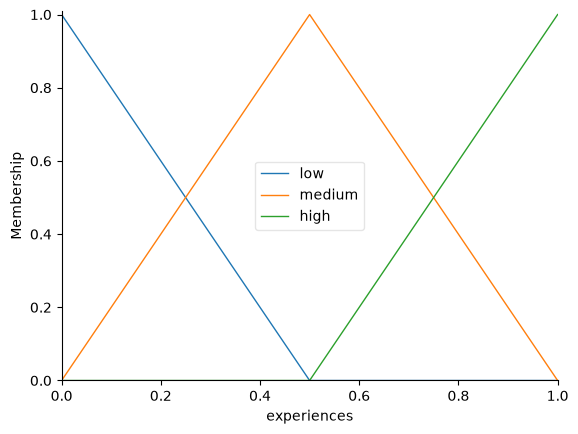

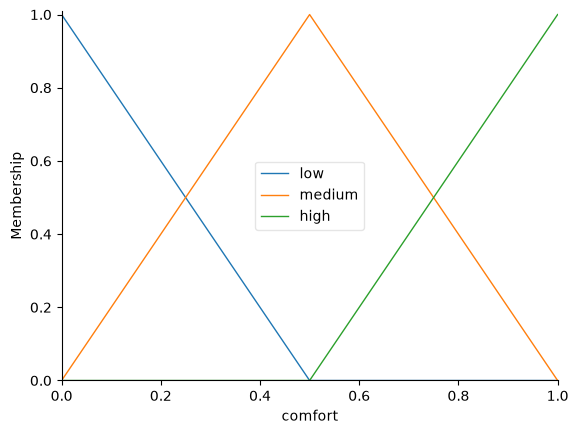

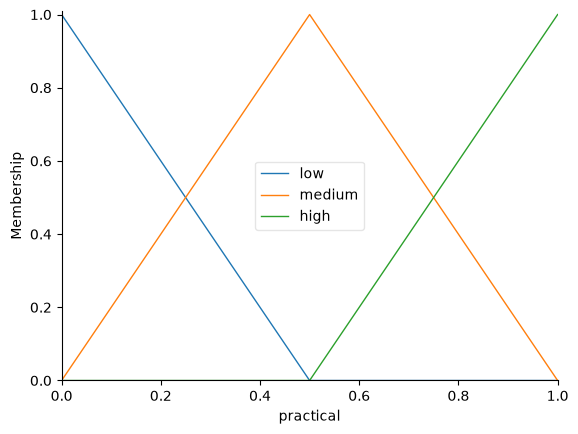

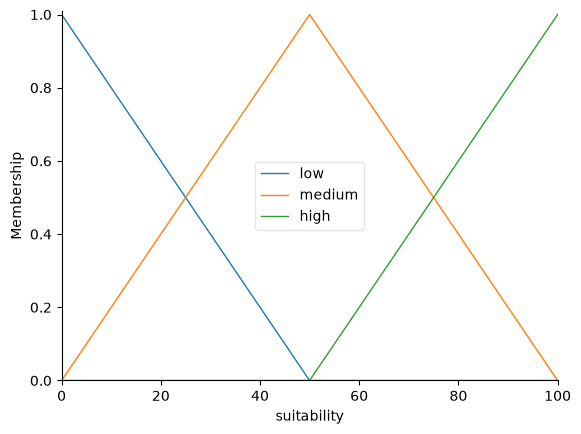

In [14]:
compatibility_universe = np.arange(0,1.001,0.01)
suitability_universe = np.arange(0,100.01,0.5)
experiences = ctrl.Antecedent(compatibility_universe,'experiences')
comfort = ctrl.Antecedent(compatibility_universe,'comfort')
practical = ctrl.Antecedent(compatibility_universe,'practical')
suitability = ctrl.Consequent(suitability_universe,'suitability')
suitability.defuzzify_method='centroid'
for var in (experiences,comfort,practical):
    var['low'] = fuzz.trimf(var.universe,[0,0,0.5])
    var['medium'] = fuzz.trimf(var.universe,[0,0.5,1])
    var['high'] = fuzz.trimf(var.universe,[0.5,1,1])
suitability['low'] = fuzz.trimf(suitability.universe,[0,0,50])
suitability['medium'] = fuzz.trimf(suitability.universe,[0,50,100])
suitability['high'] = fuzz.trimf(suitability.universe,[50,100,100])

# Classroom visualizations
experiences.view()
comfort.view()
practical.view()
suitability.view()
plt.show()

## 4. Fuzzy IF–THEN rules

The rules are constructed using `ctrl.Rule`, exactly as in the classroom examples. The 27-rule grid ensures coverage across every combination of *low/medium/high* for the three group inputs. **The consequent policy is an explicit modeling hypothesis**; it is not copied from an empirically validated tourism rule base. In particular, a low practical score prevents a high output category.

The data changes in this notebook do not alter the antecedent membership functions or the 27 rules.

In [15]:
# Two rules written explicitly, in the course style.
rule_all_high=ctrl.Rule(experiences['high'] & comfort['high'] & practical['high'],
                        suitability['high'],label='all_high')
rule_all_low=ctrl.Rule(experiences['low'] & comfort['low'] & practical['low'],
                       suitability['low'],label='all_low')

levels=('low','medium','high')
rule_list=[rule_all_high,rule_all_low]
rule_table=[]
for e,c,p in itertools.product(range(3),repeat=3):
    result=int(np.floor((e+c+p)/3+0.5))
    if p==0:
        result=min(result,1)
    rule_table.append({'experiences':levels[e], 'comfort':levels[c],
                       'practical':levels[p], 'suitability':levels[result]})
    if (e,c,p) in ((2,2,2),(0,0,0)):
        continue
    rule_list.append(ctrl.Rule(
        experiences[levels[e]] & comfort[levels[c]] & practical[levels[p]],
        suitability[levels[result]],
        label=f'exp_{levels[e]}_comfort_{levels[c]}_practical_{levels[p]}'))
assert len(rule_list)==27
sillage_ctrl=ctrl.ControlSystem(rule_list)
print('Mamdani IF–THEN rules:',len(rule_list))
display(pd.DataFrame(rule_table))

Mamdani IF–THEN rules: 27


,experiences,comfort,practical,suitability
0,low,low,low,low
1,low,low,medium,low
2,low,low,high,medium
3,low,medium,low,low
4,low,medium,medium,medium
5,low,medium,high,medium
6,low,high,low,medium
7,low,high,medium,medium
8,low,high,high,medium
9,medium,low,low,low


## 5. Run Mamdani simulations and rank cities

The **27 Mamdani rules remain unchanged**. The data pipeline now uses the enriched 50-city destination CSV and maps the 19 themes with actual questions. It uses both Profile Travel Pace answers, profile/trip preferences, landscape/climate/transport/shared-experience categories, and trip duration/traveler count for the budget constraint. Change of scenery remains a documented proxy-weight because the questionnaire does not collect the user's home environment. Rankings remain prototype simulations, not verified travel advice.

In [16]:
def grouped_scores(details):
    matches,coverage={},{}
    for group,themes in THEME_GROUPS.items():
        matches[group]=weighted_available([(details[t]['compatibility'],details[t]['weight'])
                                           for t in themes])
        coverage[group]=sum(pd.notna(details[t]['compatibility']) for t in themes)
    return matches,coverage


def rank_destinations(scenario_name,data=None):
    if scenario_name not in scenario_names:
        raise KeyError(scenario_name)
    data=cities if data is None else data  # Keep raw European categorical flags and daily cost
    ranking,diagnostics=[],[]
    for _,city_series in data.iterrows():
        city=city_series.to_dict()
        details=compare_traveler_destination(scenario_name,city)
        group,coverage=grouped_scores(details)
        budget_status=details['t18']['status']
        complete=sum(pd.notna(x['compatibility']) for x in details.values())
        partial=[t for t,x in details.items() if x['status'].startswith('partial_')]
        rec={'Scenario':scenario_name,'City':city['City'],'themes_scored':complete, 'trip_days':trip_details_answers[scenario_name]['duration_days'],
             'travellers':trip_details_answers[scenario_name]['number_of_travellers'],
             'themes_missing':19-complete,'themes_partial':', '.join(partial),
             'budget_status':budget_status,
             'estimated_trip_cost_chf':estimated_trip_cost_chf(city,trip_details_answers[scenario_name]),
             **{g+'_match':v for g,v in group.items()},
             **{g+'_coverage':v for g,v in coverage.items()}}
        if budget_status == 'budget:excluded':
            rec.update(suitability_score=np.nan,status='excluded_over_budget')
        elif any(pd.isna(v) for v in group.values()):
            rec.update(suitability_score=np.nan,status='insufficient_data')
        else:
            sim=ctrl.ControlSystemSimulation(sillage_ctrl)
            for g,v in group.items(): sim.input[g]=float(v)
            sim.compute()
            rec['suitability_score']=float(sim.output['suitability'])
            if budget_status=='budget:unknown':
                rec['status']='provisional_budget_unknown'
            elif complete<19 or partial:
                rec['status']='provisional_partial_data'
            else:
                rec['status']='complete_data_under_assumptions'
        ranking.append(rec)
        for t,x in details.items():
            diagnostics.append({'Scenario':scenario_name,'City':city['City'],
                                'Theme':t,'Name':THEME_NAMES[t],**x})
    df=pd.DataFrame(ranking).sort_values('suitability_score',ascending=False,na_position='last')
    return df.reset_index(drop=True),pd.DataFrame(diagnostics)

all_rankings=[]
for name in scenario_names:
    ranking,diagnostics=rank_destinations(name)
    all_rankings.append(ranking)
    print('\n'+name)
    display(ranking[['City','suitability_score','themes_scored','themes_missing','status']].head(3))
rankings_df=pd.concat(all_rankings,ignore_index=True)
assert rankings_df['Scenario'].nunique()==7
print('Scenarios evaluated:',rankings_df['Scenario'].nunique())


Adventure Lover


,City,suitability_score,themes_scored,themes_missing,status
0,Berlin,57.763533,18,1,provisional_partial_data
1,Bergen,57.679290,18,1,provisional_partial_data
2,Ljubljana,57.673608,18,1,provisional_partial_data



Relaxation Lover


,City,suitability_score,themes_scored,themes_missing,status
0,Rome,55.361516,18,1,provisional_partial_data
1,Seville,54.777606,18,1,provisional_partial_data
2,Antalya,54.722386,18,1,provisional_partial_data



Food Explorer


,City,suitability_score,themes_scored,themes_missing,status
0,Paris,59.602680,18,1,provisional_partial_data
1,Krakow,58.351565,18,1,provisional_partial_data
2,Rome,58.131591,18,1,provisional_partial_data


... (5 outputs left out)

,City,suitability_score,themes_scored,themes_missing,status
0,Ljubljana,56.245437,18,1,provisional_partial_data
1,Krakow,55.451703,18,1,provisional_partial_data
2,Szeged,53.745276,18,1,provisional_partial_data



Adventure Preference Change


,City,suitability_score,themes_scored,themes_missing,status
0,Berlin,55.918679,18,1,provisional_partial_data
1,Oslo,55.643874,18,1,provisional_partial_data
2,Gothenburg,55.595364,18,1,provisional_partial_data


Scenarios evaluated: 7


## 6. Inspect individual themes and test sensitivity

The audit is indispensable: one overall score does not show which assumptions or missing data drove it. The seven scenarios are **synthetic tests**, not user validation.

Example scenario: Adventure Lover — city: Berlin


,Theme,Name,compatibility,weight,status
304,t1,Change of Scenery,NaN,1.000000,novelty_weight_only_no_home_environment
305,t2,Food / Gastronomy,0.880000,0.447500,importance_weighted_benefit
306,t3,Authenticity,0.860000,1.000000,authenticity_category_proxy
307,t4,Relaxation,0.192308,1.000000,level
308,t6,Must-see Landmarks,0.420000,0.433333,importance_weighted_benefit
309,t7,Infrastructure,0.995000,1.000000,tolerance
310,t8,Drinking Water / Hygiene,0.880000,1.000000,tolerance
311,t12,Unique Experiences,0.930000,0.974500,importance_weighted_benefit
312,t13,Beautiful Landscapes,0.810000,0.915000,partial_landscape_quality_only
313,t14,Travel Pace,0.736873,1.000000,profile_two_answers_and_trip_pace


Adventure Lover → Adventurer Seeking Relaxation: max |Δ score| = 5.962
Adventure Lover → Adventure Preference Change: max |Δ score| = 5.962
Balanced Traveler → Budget-Constrained Traveler: max |Δ score| = 3.576


c:\Users\Loan\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


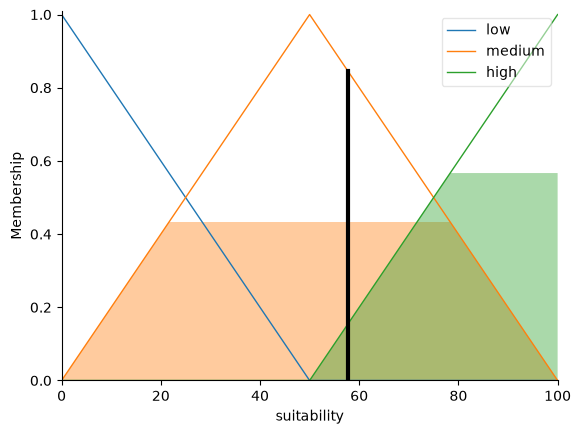

In [17]:
example_name='Adventure Lover'
first_rank,first_details=rank_destinations(example_name)
first_city=first_rank.iloc[0]['City']
print('Example scenario:',example_name,'— city:',first_city)
display(first_details[first_details['City']==first_city][['Theme','Name','compatibility','weight','status']])

# Quick diagnostics for the three controlled scenario comparisons.
for a,b in [('Adventure Lover','Adventurer Seeking Relaxation'),
            ('Adventure Lover','Adventure Preference Change'),
            ('Balanced Traveler','Budget-Constrained Traveler')]:
    a_rank,_=rank_destinations(a)
    b_rank,_=rank_destinations(b)
    merged=a_rank[['City','suitability_score']].merge(
        b_rank[['City','suitability_score']],on='City',suffixes=('_before','_after'))
    differences=(merged['suitability_score_after']-merged['suitability_score_before']).abs()
    print(f'{a} → {b}: max |Δ score| = {differences.max():.3f}'
          if differences.notna().any() else f'{a} → {b}: scores unavailable')

# Optional class-style visualization for a single simulated city:
row=first_rank.iloc[0]
if pd.notna(row['suitability_score']):
    sim=ctrl.ControlSystemSimulation(sillage_ctrl)
    for group in THEME_GROUPS:
        sim.input[group]=float(row[group+'_match'])
    sim.compute()
    suitability.view(sim=sim)
    plt.show()

### Sources used for this implementation

- `01_FuzzyControlSystem.ipynb` — `skfuzzy.control` workflow, variables, IF–THEN rules, control system and centroid defuzzification.
- `03_FuzzyVacationPlanner.ipynb` — separate personality and current-trip inputs, `trimf`, rule simulation and output visualization.
- `02_FuzzyClustering.ipynb` — illustrates fuzzy memberships, **not used** as the recommendation algorithm.
- `03_Sillage_devoir_tuto.ipynb` — illustrative traveler–destination compatibility before fuzzy inference.
- `Sillage_fuzzy_model_evaluation.ipynb` and `Cities.csv` — unchanged group profiles, seven scenarios, 19 topics and current dataset.

## 7. Technical Validation and Simulation

Seven synthetic scenarios are evaluated against the 50 European destinations. Budget screening uses each scenario's entered trip duration and number of travelers, with an explicitly illustrative EUR→CHF conversion factor. PASS/FAIL applies only to the narrow technical checks; synthetic destination attributes do not establish real-world recommendation accuracy.

### 7.1. Expected vs. Actual Results

We use all seven predefined scenarios. The **Expected** column is specified independently of the actual rankings. **Actual** reports top-ranked destinations, score ranges and coverage; it does not itself constitute a validation pass. A separate automated test table follows.

In [18]:
# Run after the previous cells have created rankings_df, scenario_names and all model functions.
SCENARIO_EXPECTATIONS = {
    'Adventure Lover': 'Destinations offering more physical activities should fit this profile better, all else equal.',
    'Relaxation Lover': 'Destinations offering more relaxation should fit this profile better, all else equal.',
    'Food Explorer': 'Gastronomy is weighted more strongly than for the Balanced Traveler.',
    'Balanced Traveler': 'A mixed profile should produce finite, reproducible scores without a missing group.',
    'Adventurer Seeking Relaxation': 'Compared with Adventure Lover, current-trip relaxation preferences should change relevant compatibility scores.',
    'Budget-Constrained Traveler': "Destinations above CHF 700 in this scenario's entered trip-cost estimate must be excluded.",
    'Adventure Preference Change': 'Changing only trip activity from high to low should alter t24 compatibility.'
}

# Reuse the rankings already produced by the original notebook.
all_rankings_by_name = {name: rankings_df[rankings_df['Scenario'] == name].copy()
                        for name in scenario_names}
# Collect theme-level diagnostics for controlled comparisons.
all_diagnostics = {}
for name in scenario_names:
    _, details = rank_destinations(name)
    all_diagnostics[name] = details

result_rows = []
for name in scenario_names:
    df = all_rankings_by_name[name]
    valid = df[df['suitability_score'].notna()].sort_values('suitability_score', ascending=False)
    top = ', '.join(valid['City'].head(3).tolist()) if len(valid) else 'No scored cities'
    score_range = (f"{valid['suitability_score'].min():.1f}–{valid['suitability_score'].max():.1f}"
                   if len(valid) else 'N/A')
    result_rows.append({
        'Scenario': name,
        'Expected behavior': SCENARIO_EXPECTATIONS[name],
        'Actual: top 3': top,
        'Actual: score range': score_range,
        'Scored cities': len(valid),
        'Complete 19/19': int((df['themes_scored'].eq(19) & df['themes_partial'].eq('') &
                                df['budget_status'].ne('budget:unknown')).sum()),
        'Budget excluded': int(df['status'].eq('excluded_over_budget').sum())
    })
expected_actual = pd.DataFrame(result_rows)
display(expected_actual)


,Scenario,Expected behavior,Actual: top 3,Actual: score range,Scored cities,Complete 19/19,Budget excluded
0,Adventure Lover,Destinations offering more physical activities...,"Berlin, Bergen, Ljubljana",50.0–57.8,50,0,0
1,Relaxation Lover,Destinations offering more relaxation should f...,"Rome, Seville, Antalya",50.0–55.4,50,0,0
2,Food Explorer,Gastronomy is weighted more strongly than for ...,"Paris, Krakow, Rome",50.5–59.6,50,0,0
3,Balanced Traveler,"A mixed profile should produce finite, reprodu...","London, Dublin, Rotterdam",51.1–62.1,50,0,0
4,Adventurer Seeking Relaxation,"Compared with Adventure Lover, current-trip re...","Berlin, Oslo, Gothenburg",50.0–55.9,50,0,0
5,Budget-Constrained Traveler,Destinations above CHF 700 in this scenario's ...,"Ljubljana, Krakow, Szeged",51.6–56.2,5,0,45
6,Adventure Preference Change,Changing only trip activity from high to low s...,"Berlin, Oslo, Gothenburg",49.8–55.9,50,0,0


### 7.2. Automated consistency tests (PASS / FAIL / INCONCLUSIVE)

The assertions are deliberately narrow. We check **theme-level responses** for the controlled one-variable modifications, not an unjustified requirement that every entire ranking must change in a predetermined direction. An equal final Mamdani score may conceal different intermediate matches. Budget enforcement cannot be asserted from the original destination dataset because it contains no comparable trip-level costs in CHF.

In [19]:
# Reusable diagnostics and validation helpers
EPS = 1e-8

def theme_scores(scenario, theme):
    diag = all_diagnostics[scenario]
    out = diag[diag['Theme'] == theme][['City', 'compatibility', 'weight', 'status']].copy()
    return out.drop_duplicates(subset=['City']).set_index('City')


def changed_theme(a, b, theme):
    x, y = theme_scores(a, theme), theme_scores(b, theme)
    df = x[['compatibility']].join(y[['compatibility']], how='inner',
                                    lsuffix='_before', rsuffix='_after')
    df['delta'] = df['compatibility_after'] - df['compatibility_before']
    return df


def add_test(rows, scenario, criterion, passed=None, evidence='', reason=''):
    status = 'INCONCLUSIVE' if passed is None else ('PASS' if bool(passed) else 'FAIL')
    rows.append({'Scenario': scenario, 'Test': criterion, 'Status': status,
                 'Evidence': evidence, 'Limitation': reason})

validation_rows = []

# Technical invariants common to every scenario
for name in scenario_names:
    r = all_rankings_by_name[name]
    finite = r['suitability_score'].dropna()
    add_test(validation_rows, name, 'Valid fuzzy output range 0–100',
             len(finite) > 0 and finite.between(0, 100).all(),
             f'{len(finite)}/{len(r)} scored; range '
             + (f'{finite.min():.2f}–{finite.max():.2f}' if len(finite) else 'N/A'))

# 1: A very active traveler should match high-activity cities better at theme t24.
a = theme_scores('Adventure Lover', 't24').join(cities.set_index('City')[['t24']])
high = a.loc[a['t24'] >= 0.70, 'compatibility'].dropna()
low = a.loc[a['t24'] <= 0.30, 'compatibility'].dropna()
add_test(validation_rows, 'Adventure Lover', 'Higher t24 match for high-activity cities',
         float(high.mean()) > float(low.mean()) + EPS if len(high) and len(low) else None,
         f'mean high={high.mean():.3f}; mean low={low.mean():.3f}',
         'Requires cities on both ends of the activity scale' if not len(high) or not len(low) else '')

# 2: A relaxation-oriented traveler should match high-relaxation cities better at theme t4.
a = theme_scores('Relaxation Lover', 't4').join(cities.set_index('City')[['t4']])
high = a.loc[a['t4'] >= 0.70, 'compatibility'].dropna()
low = a.loc[a['t4'] <= 0.30, 'compatibility'].dropna()
add_test(validation_rows, 'Relaxation Lover', 'Higher t4 match for high-relaxation cities',
         float(high.mean()) > float(low.mean()) + EPS if len(high) and len(low) else None,
         f'mean high={high.mean():.3f}; mean low={low.mean():.3f}',
         'Requires cities on both ends of the relaxation scale' if not len(high) or not len(low) else '')

# 3: Food interest must meaningfully affect the gastronomy weight.
fw = theme_scores('Food Explorer', 't2')['weight']
bw = theme_scores('Balanced Traveler', 't2')['weight']
common = fw.index.intersection(bw.index)
add_test(validation_rows, 'Food Explorer', 'Gastronomy weight exceeds Balanced Traveler',
         bool((fw.loc[common] > bw.loc[common] + EPS).all()) if len(common) else None,
         f'Food mean weight={fw.mean():.3f}, balanced={bw.mean():.3f}')

# 4: Recalculate one city, verifying deterministic inference at fixed inputs.
r, _ = rank_destinations('Balanced Traveler')
orig = all_rankings_by_name['Balanced Traveler'].set_index('City')['suitability_score']
again = r.set_index('City')['suitability_score'].reindex(orig.index)
valid = orig.notna() & again.notna()
repeat_delta = (orig[valid] - again[valid]).abs()
add_test(validation_rows, 'Balanced Traveler', 'Repeated inputs give the same score',
         bool((repeat_delta <= 1e-6).all()) if valid.any() else None,
         f'max |Δ|={repeat_delta.max():.8f}' if valid.any() else 'No comparable scores')

# 5: Trip preference modification must influence at least one relevant theme score.
changed = [changed_theme('Adventure Lover', 'Adventurer Seeking Relaxation', t)
           for t in ('t4', 't14', 't24')]
n_changed = [int((d['delta'].abs() > EPS).sum()) for d in changed]
add_test(validation_rows, 'Adventurer Seeking Relaxation',
         'Changing trip plans changes relevant theme matches',
         sum(n_changed) > 0,
         f'Cities with changed t4/t14/t24: {n_changed}')

# 6: Budget hard-cap verification using the scenario's entered duration and traveler count.
# The dataset provides an estimated daily cost in EUR, NOT an actual trip price in CHF.
limited = all_rankings_by_name['Budget-Constrained Traveler']
budget_details = trip_details_answers['Budget-Constrained Traveler']
base_costs = (
    cities.set_index('City')['daily_cost_eur_estimate'].astype(float)
    * budget_details['duration_days']
    * budget_details['number_of_travellers']
    * EUR_TO_CHF_ILLUSTRATIVE
)
costs = base_costs.reindex(limited['City']).to_numpy()
if np.isfinite(costs).all() and (costs > 700).any():
    over = limited.loc[costs > 700]
    excl = over['status'].eq('excluded_over_budget')
    add_test(validation_rows, 'Budget-Constrained Traveler',
             'Synthetic assumed trip costs above CHF 700 are excluded',
             bool(excl.all()), f'{int(excl.sum())}/{len(over)} excluded',
             'Only proves behavior under synthetic daily costs and the entered trip details / illustrative exchange factor')
else:
    add_test(validation_rows, 'Budget-Constrained Traveler',
             'Synthetic assumed trip costs above CHF 700 are excluded', None,
             'No usable over-budget cities',
             'Need complete cost proxy and at least one over-budget city')

# 7: One-variable change in trip t24 must change the t24 compatibility where measurable.
d = changed_theme('Adventure Lover', 'Adventure Preference Change', 't24')
add_test(validation_rows, 'Adventure Preference Change',
         'Changing only trip t24 affects t24 compatibility',
         bool((d['delta'].abs() > EPS).any()) if d['delta'].notna().any() else None,
         f"{int((d['delta'].abs() > EPS).sum())} / {int(d['delta'].notna().sum())} city matches changed")

# Display results; FAIL means observed test criterion did not hold; INCONCLUSIVE means insufficient data.
validation_df = pd.DataFrame(validation_rows)
display(validation_df)
print('Validation status counts:')
print(validation_df['Status'].value_counts().to_string())


C:\Users\Loan\AppData\Local\Temp\ipykernel_17544\2280994606.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  df = x[['compatibility']].join(y[['compatibility']], how='inner',
C:\Users\Loan\AppData\Local\Temp\ipykernel_17544\2280994606.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  df = x[['compatibility']].join(y[['compatibility']], how='inner',
C:\Users\Loan\AppData\Local\Temp\ipykernel_17544\2280994606.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  df = x[['compatibility']].join(y[['compatibility']], how='inner',
C:\Users\Loan\AppData\Local\Temp\ipykernel_17544\2280994606.py:12: Pandas4Warning: The 'lsuffix' and 'rsuf

,Scenario,Test,Status,Evidence,Limitation
0,Adventure Lover,Valid fuzzy output range 0–100,PASS,50/50 scored; range 49.99–57.76,
1,Relaxation Lover,Valid fuzzy output range 0–100,PASS,50/50 scored; range 50.03–55.36,
2,Food Explorer,Valid fuzzy output range 0–100,PASS,50/50 scored; range 50.49–59.60,
3,Balanced Traveler,Valid fuzzy output range 0–100,PASS,50/50 scored; range 51.11–62.06,
4,Adventurer Seeking Relaxation,Valid fuzzy output range 0–100,PASS,50/50 scored; range 50.00–55.92,
5,Budget-Constrained Traveler,Valid fuzzy output range 0–100,PASS,5/50 scored; range 51.65–56.25,
6,Adventure Preference Change,Valid fuzzy output range 0–100,PASS,50/50 scored; range 49.85–55.92,
7,Adventure Lover,Higher t24 match for high-activity cities,PASS,mean high=0.646; mean low=0.038,
8,Relaxation Lover,Higher t4 match for high-relaxation cities,INCONCLUSIVE,mean high=0.842; mean low=nan,Requires cities on both ends of the relaxation...
9,Food Explorer,Gastronomy weight exceeds Balanced Traveler,PASS,"Food mean weight=0.958, balanced=0.575",


Validation status counts:
Status
PASS            13
INCONCLUSIVE     1


### 7.3. Comparative figures

The first figure compares the best observed scores for each scenario. It is descriptive, **not** evidence that those destinations are correct. The second figure compares the **same destinations** under a controlled input change; the third summarizes test outcomes. These plots are computed from results, not manually entered numbers.

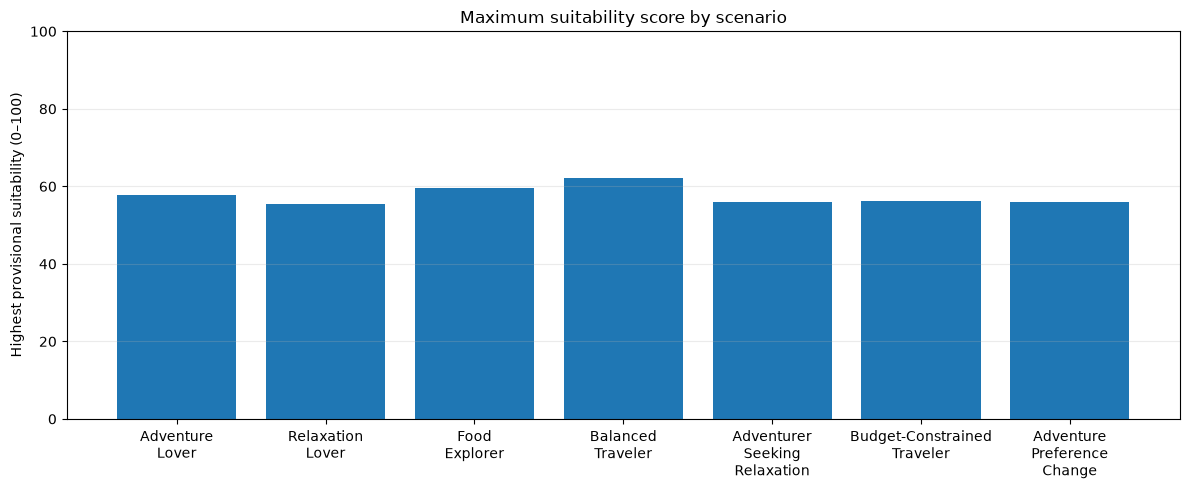

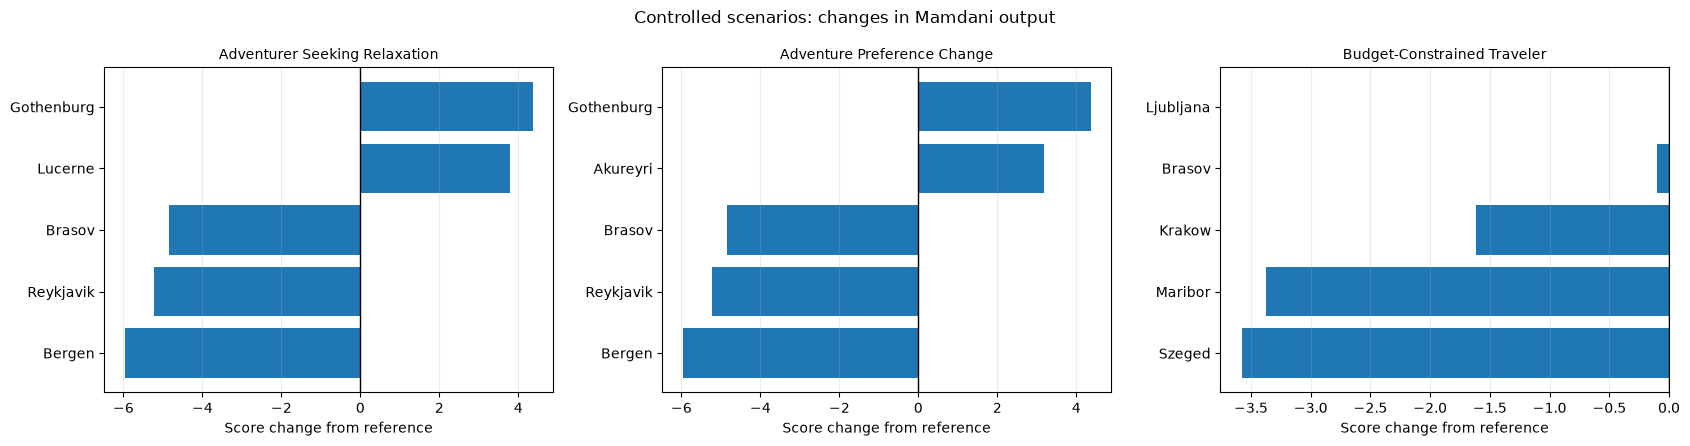

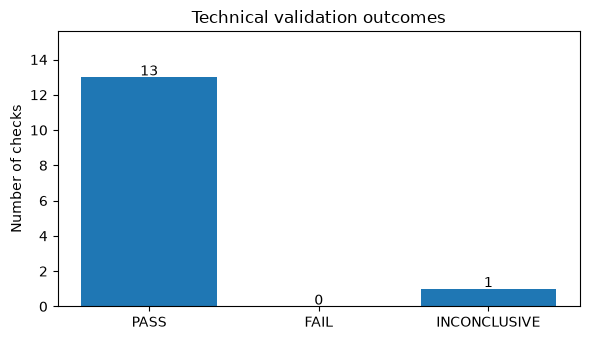

In [20]:
# Figure 1 — strongest scored destination for each scenario
fig, ax = plt.subplots(figsize=(12, 5))
plot = (rankings_df.groupby('Scenario', sort=False)['suitability_score']
        .max().reindex(scenario_names))
ax.bar(range(len(plot)), plot.values)
ax.set_xticks(range(len(plot)), [s.replace(' ', '\n') for s in plot.index], rotation=0)
ax.set_ylim(0, 100)
ax.set_ylabel('Highest provisional suitability (0–100)')
ax.set_title('Maximum suitability score by scenario')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

# Figure 2 — compare the same destinations before and after a controlled preference change
pairs = [
    ('Adventure Lover', 'Adventurer Seeking Relaxation'),
    ('Adventure Lover', 'Adventure Preference Change'),
    ('Balanced Traveler', 'Budget-Constrained Traveler')
]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (before, after) in zip(axes, pairs):
    a = all_rankings_by_name[before].set_index('City')['suitability_score']
    b = all_rankings_by_name[after].set_index('City')['suitability_score']
    common = a.index.intersection(b.index)
    delta = (b.loc[common] - a.loc[common]).dropna().sort_values()
    if len(delta):
        # Top five cities with largest absolute changes, kept in sorted display order
        shown = delta.loc[delta.abs().nlargest(min(5, len(delta))).index].sort_values()
        ax.barh(shown.index, shown.values)
    else:
        ax.text(0.5, 0.5, 'No comparable scores', transform=ax.transAxes,
                ha='center', va='center')
    ax.axvline(0, linewidth=1, color='black')
    ax.set_title(after, fontsize=10)
    ax.set_xlabel('Score change from reference')
    ax.grid(axis='x', alpha=0.25)
plt.suptitle('Controlled scenarios: changes in Mamdani output')
plt.tight_layout()
plt.show()

# Figure 3 — validation outcomes, including explicitly inconclusive tests
counts = validation_df['Status'].value_counts().reindex(
    ['PASS', 'FAIL', 'INCONCLUSIVE'], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index, counts.values)
ax.set_ylabel('Number of checks')
ax.set_title('Technical validation outcomes')
for i, val in enumerate(counts.values):
    ax.text(i, val + 0.1, str(val), ha='center')
ax.set_ylim(0, max(counts.max() * 1.2, 1))
plt.tight_layout()
plt.show()


## 8. Results and Discussion

The interpretations below are generated from the observed tests. **PASS** means the narrow test condition was satisfied; it does not establish that the real-world destination recommendation is correct. **FAIL** exposes a mismatch with a predeclared expectation. **INCONCLUSIVE** means the dataset cannot establish the claim. The 19 themes are represented in the questionnaire mapping, but some cannot be fully evaluated without real categorical and budget information.

In [21]:
# Generated discussion based on actual validation outcomes
counts = validation_df['Status'].value_counts()
passed = int(counts.get('PASS', 0))
failed = int(counts.get('FAIL', 0))
inconclusive = int(counts.get('INCONCLUSIVE', 0))

print('RESULTS AND DISCUSSION')
print(f'The automated checks returned {passed} PASS, {failed} FAIL, '
      f'and {inconclusive} INCONCLUSIVE results.')
print(f'The model generated provisional destination scores for '
      f"{rankings_df['Scenario'].nunique()} synthetic scenarios. "
      'The synthetic European dataset does not establish actual destination suitability.')

print('\nSUPPORTED FINDINGS:')
for _, item in validation_df[validation_df['Status'] == 'PASS'].iterrows():
    print(f"- {item['Scenario']}: {item['Test']} ({item['Evidence']}).")

print('\nFAILED CHECKS:')
for _, item in validation_df[validation_df['Status'] == 'FAIL'].iterrows():
    print(f"- {item['Scenario']}: {item['Test']} ({item['Evidence']}).")
if not failed:
    print('- None of the defined checks failed; this does not prove general validity.')

print('\nUNVERIFIABLE CLAIMS:')
for _, item in validation_df[validation_df['Status'] == 'INCONCLUSIVE'].iterrows():
    print(f"- {item['Scenario']}: {item['Test']} — {item['Limitation']}.")
if not inconclusive:
    print('- None in the currently implemented checks.')

print('\nLIMITATIONS AND NEXT IMPROVEMENTS:')
print('- City theme scores are synthetic, not validated travel facts.')
print('- Landscape and climate flags are available. Shared-experience and authenticity fields are derived proxies; transport-mode flags are currently constant across cities.')
print('- Budget uses synthetic daily EUR cost multiplied by each scenario’s entered duration and traveler count, with illustrative FX factor 1.0.')
print('- Ages and date flexibility are retained/validated but do not adjust costs or seasonal climate because the CSV lacks age-based prices and monthly climate data.')
print('- Some themes cannot be observed; consult themes_missing and themes_partial.')
print('- The three aggregated dimensions, weights and 27 IF–THEN rules are design assumptions.')
print('- Add real data for unmatched questionnaire themes and verified costs matched to party/dates/duration,')
print('  a larger set of controlled perturbation tests and user evaluation.')


RESULTS AND DISCUSSION
The automated checks returned 13 PASS, 0 FAIL, and 1 INCONCLUSIVE results.
The model generated provisional destination scores for 7 synthetic scenarios. The synthetic European dataset does not establish actual destination suitability.

SUPPORTED FINDINGS:
- Adventure Lover: Valid fuzzy output range 0–100 (50/50 scored; range 49.99–57.76).
- Relaxation Lover: Valid fuzzy output range 0–100 (50/50 scored; range 50.03–55.36).
- Food Explorer: Valid fuzzy output range 0–100 (50/50 scored; range 50.49–59.60).
- Balanced Traveler: Valid fuzzy output range 0–100 (50/50 scored; range 51.11–62.06).
- Adventurer Seeking Relaxation: Valid fuzzy output range 0–100 (50/50 scored; range 50.00–55.92).
- Budget-Constrained Traveler: Valid fuzzy output range 0–100 (5/50 scored; range 51.65–56.25).
- Adventure Preference Change: Valid fuzzy output range 0–100 (50/50 scored; range 49.85–55.92).
- Adventure Lover: Higher t24 match for high-activity cities (mean high=0.646; mean low=

### Results and Discussion

We tested our fuzzy recommendation system using seven different traveler scenarios and 50 European destinations.

Overall, 13 tests passed, none failed, and one was inconclusive. The model produced scores between 0 and 100 and gave different recommendations depending on the travelers' preferences.

The budget test also worked under our synthetic cost assumptions, excluding 45 destinations that exceeded the maximum budget.

However, we noticed some limitations. The relaxation test was inconclusive because there were not enough low-relaxation destinations to make a comparison. Also, none of the destinations had complete information for all 19 themes.

Another observation is that the suitability scores stayed relatively close to each other, mostly between 50 and 65. This could limit how well the model distinguishes different destinations.

These results show that our fuzzy system behaves consistently in several situations, but more testing and better destination data are needed before we can consider the recommendations fully reliable.

### 8.1. Summary for the report (complete after executing)

**Method.** We evaluated our 27-rule Mamdani fuzzy recommendation system on seven synthetic traveler scenarios, using 50 European destinations from a synthetic prototype CSV. We mapped 19 questionnaire themes to the attributes that the dataset actually supports. We used explicit assumptions for an illustrative seven-day budget proxy.

**Results.** Fill in the PASS, FAIL and INCONCLUSIVE counts from the automatically generated table. Report at least one relevant score comparison and one observed limitation. A PASS on an input-response test does not prove that a real destination is suitable.

**Limitations.** Destination scores are synthetic. Change of scenery cannot be assessed without the origin, and several categorical questions lack full matching attributes. Trip cost is estimated from assumed duration and an illustrative conversion factor, not verified for party size or season.

**Next steps.** Test real destination data, season-specific climate, verified prices and richer category matches; include additional perturbation and user testing.
